In [1]:
import pandas as pd #pandas organizes that data into a clean,readable table,manipulating the data.
import numpy as np #numpy works with the numerical and mathematical part,handles the underlying mat and raw arrays
import seaborn as sns #builds beautiful statistical charts out of your data table quickly to visualize the data.
import matplotlib.pyplot as plt #matplotlib fine-tunes the charts specific details(labels,limits and sizes)before you save it.
import warnings 
warnings.filterwarnings("ignore") # Hide warning messages.

# Domain Analysis

__Bussiness Case__: 
* Flight ticket prices can be something hard to guess, today we might see a price, check out the price of the same flight tomorrow, it will be a different story. We might have often heard travelers saying that flight ticket prices are so unpredictable. That’s why we will try to use machine learning to solve this problem. This can help airlines by predicting what prices they can maintain.

# Attribute Information : 

1.	Airline: So this column will have all the types of airlines like Indigo, Jet Airways, Air India, and many more.  

2.	Date_of_Journey: This column will let us know about the date on which the passenger’s journey will start.

3.	Source: This column holds the name of the place from where the passenger’s journey will start.

4.	Destination: This column holds the name of the place to where passengers wanted to travel.

5.	Route: Here we can know about what the route is through which passengers have opted to travel from his/her source to       their destination.

6.	Arrival_Time: Arrival time is when the passenger will reach his/her destination.

7.	Duration: Duration is the whole period that a flight will take to complete its journey from source to destination.

8.	Total_Stops: This will let us know in how many places flights will stop there for the flight in the whole journey.

9.	Additional_Info: In this column, we will get information about food, kind of food, and other amenities.

10.	Price: Price of the flight for a complete journey including all the expenses before onboarding.


In [2]:
df = pd.read_excel("Flight_Fare.xlsx") # Read the Flight Fare Excel file into a DataFrame

In [3]:
df.head() # displays the first 5 rows by default.

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [4]:
pd.set_option('display.max_columns',None) #Show all columns instead of hiding some columns.

# Basic Checks:

In [5]:
df.info() # Display dataset columns, data types, and missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [6]:
df.describe() ## Generate statistical summary of numerical columns

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [7]:
df.describe(include="O") ## Generate statistical summary of Categorical columns

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
count,10683,10683,10683,10683,10682,10683,10683,10683,10682,10683
unique,12,44,5,6,128,222,1343,368,5,10
top,Jet Airways,18/05/2019,Delhi,Cochin,DEL → BOM → COK,18:55,19:00,2h 50m,1 stop,No info
freq,3849,504,4537,4537,2376,233,423,550,5625,8345


* The dataset contains 11 columns, with only Price being numerical.
* Jet Airways is the most frequent airline
* Route and Total_Stops each contain only 1 missing value, which can be removed safely.
* most off flight is take off delhi and land off Cochin.
* The most common route is DEL → BOM → COK.
* Around 50% of flights have 1 stop, making it the most common stop category in the dataset.
* Approximately 80% of the records contain "No info" in the Additional_Info column. Therefore, this feature provides limited useful information and can be considered for removal during preprocessing.

# EDA (Exploratory Data Analysis) :


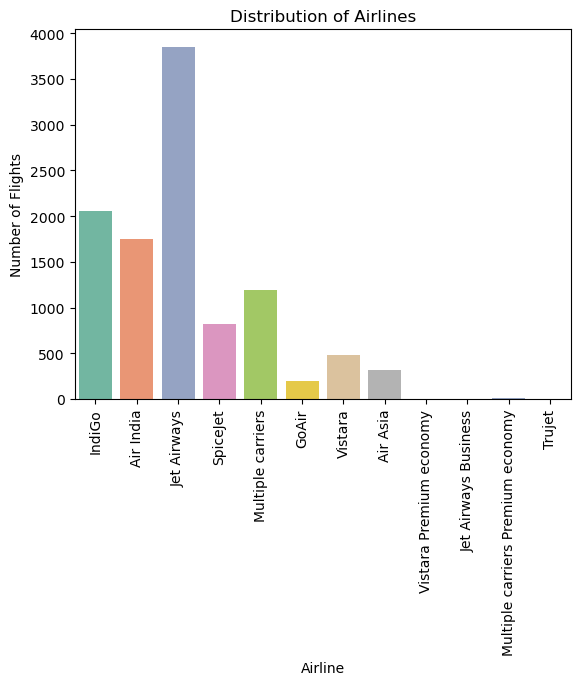

In [8]:
sns.countplot(x =df.Airline, palette='Set2') ## Create a count plot to show the number of flights for each airline
plt.xticks(rotation= 90) # Rotate airline names by 90 degrees for better readability
plt.ylabel("Number of Flights") # Set the Y-axis label as Number of Flights
plt.title("Distribution of Airlines") # Set the title of the graph
plt.show()# Display the graph

* Insights:
    * Jet Airways has the highest number of flights, while other airlines have comparatively fewer flights.

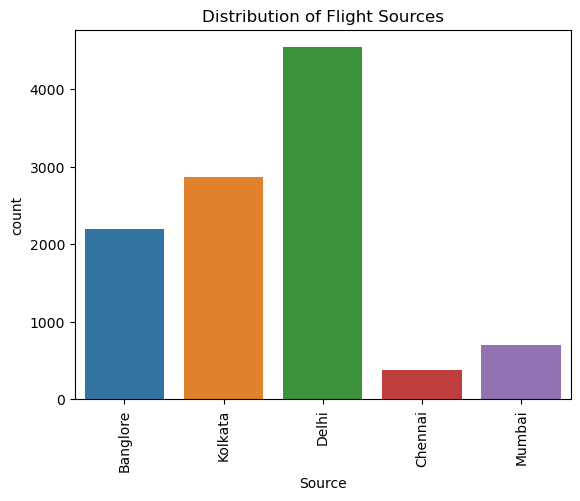

In [9]:
sns.countplot(x=df.Source, hue= df.Source) #Counts each flight source and shows it as a bar chart.
plt.xticks(rotation = 90) # Rotate Source names by 90 degrees for better readability.
plt.title("Distribution of Flight Sources") ## Set the title of the chart.
plt.show() #display the graph.

* Insights:
  * Delhi has the highest number of flights.

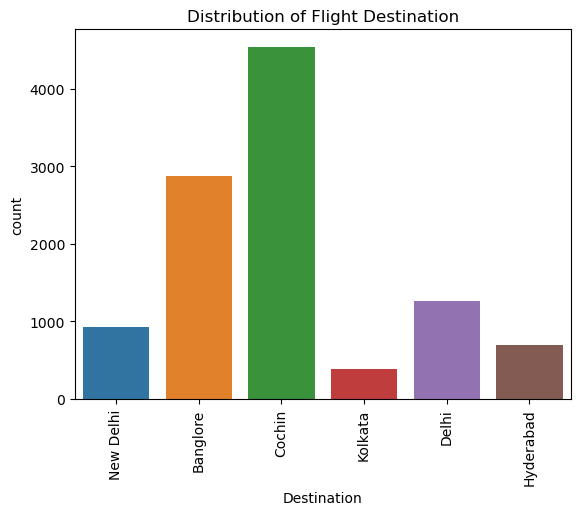

In [10]:
sns.countplot(x=df.Destination, hue=df.Destination)  # Count flights for each destination
plt.xticks(rotation=90)  # Rotate destination names for readability
plt.title("Distribution of Flight Destination")  # Add chart title
plt.show()  # Display the graph

* Insights:
  * Cochin has the highest number of flights.

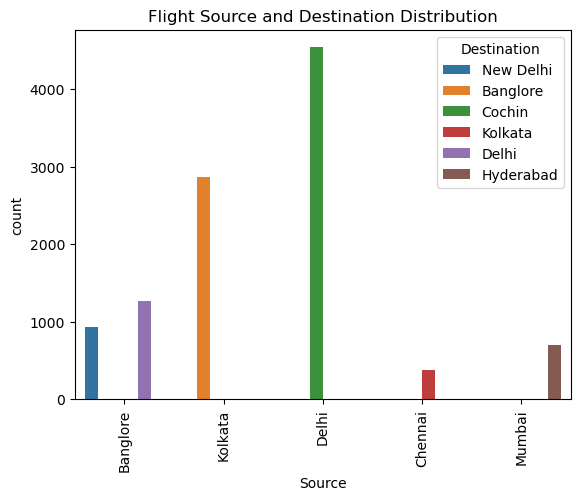

In [11]:
sns.countplot(x=df.Source, hue=df.Destination)  # Show flights by source and destination
plt.xticks(rotation=90)  # Rotate source names for readability
plt.title("Flight Source and Destination Distribution")  # Add chart title
plt.show()  # Display the graph

* Insights:
  * Delhi is the most common destination from most sources.

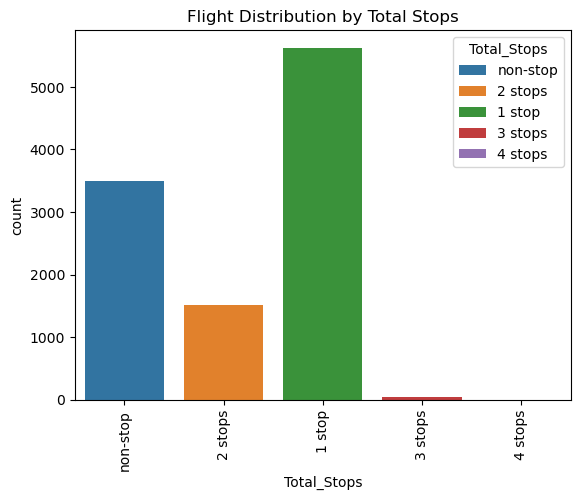

In [12]:
sns.countplot(x=df.Total_Stops, hue=df.Total_Stops)  # Count flights by total stops
plt.xticks(rotation=90)  # Rotate labels for readability
plt.title("Flight Distribution by Total Stops")  # Add chart title
plt.show()  # Display the graph

* Insights:
  * Most flights have 1 stop.

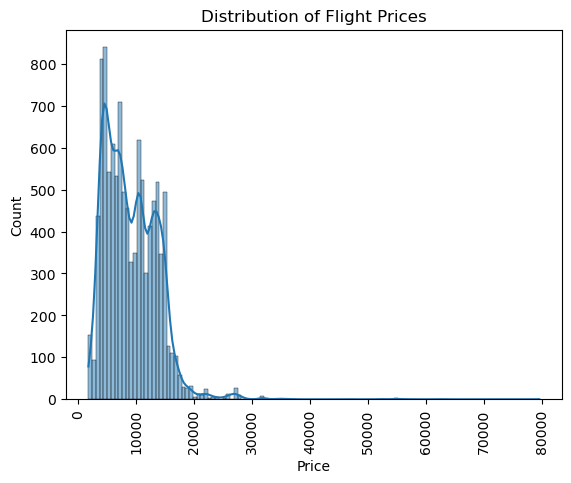

In [13]:
sns.histplot(df.Price, kde=True)  # Show the distribution of flight prices
plt.xticks(rotation=90)  # Rotate X-axis labels
plt.title("Distribution of Flight Prices")  # Add chart title
plt.show()  # Display the graph

* Insights:
  * Most flight prices are concentrated in the lower-to-middle price range.

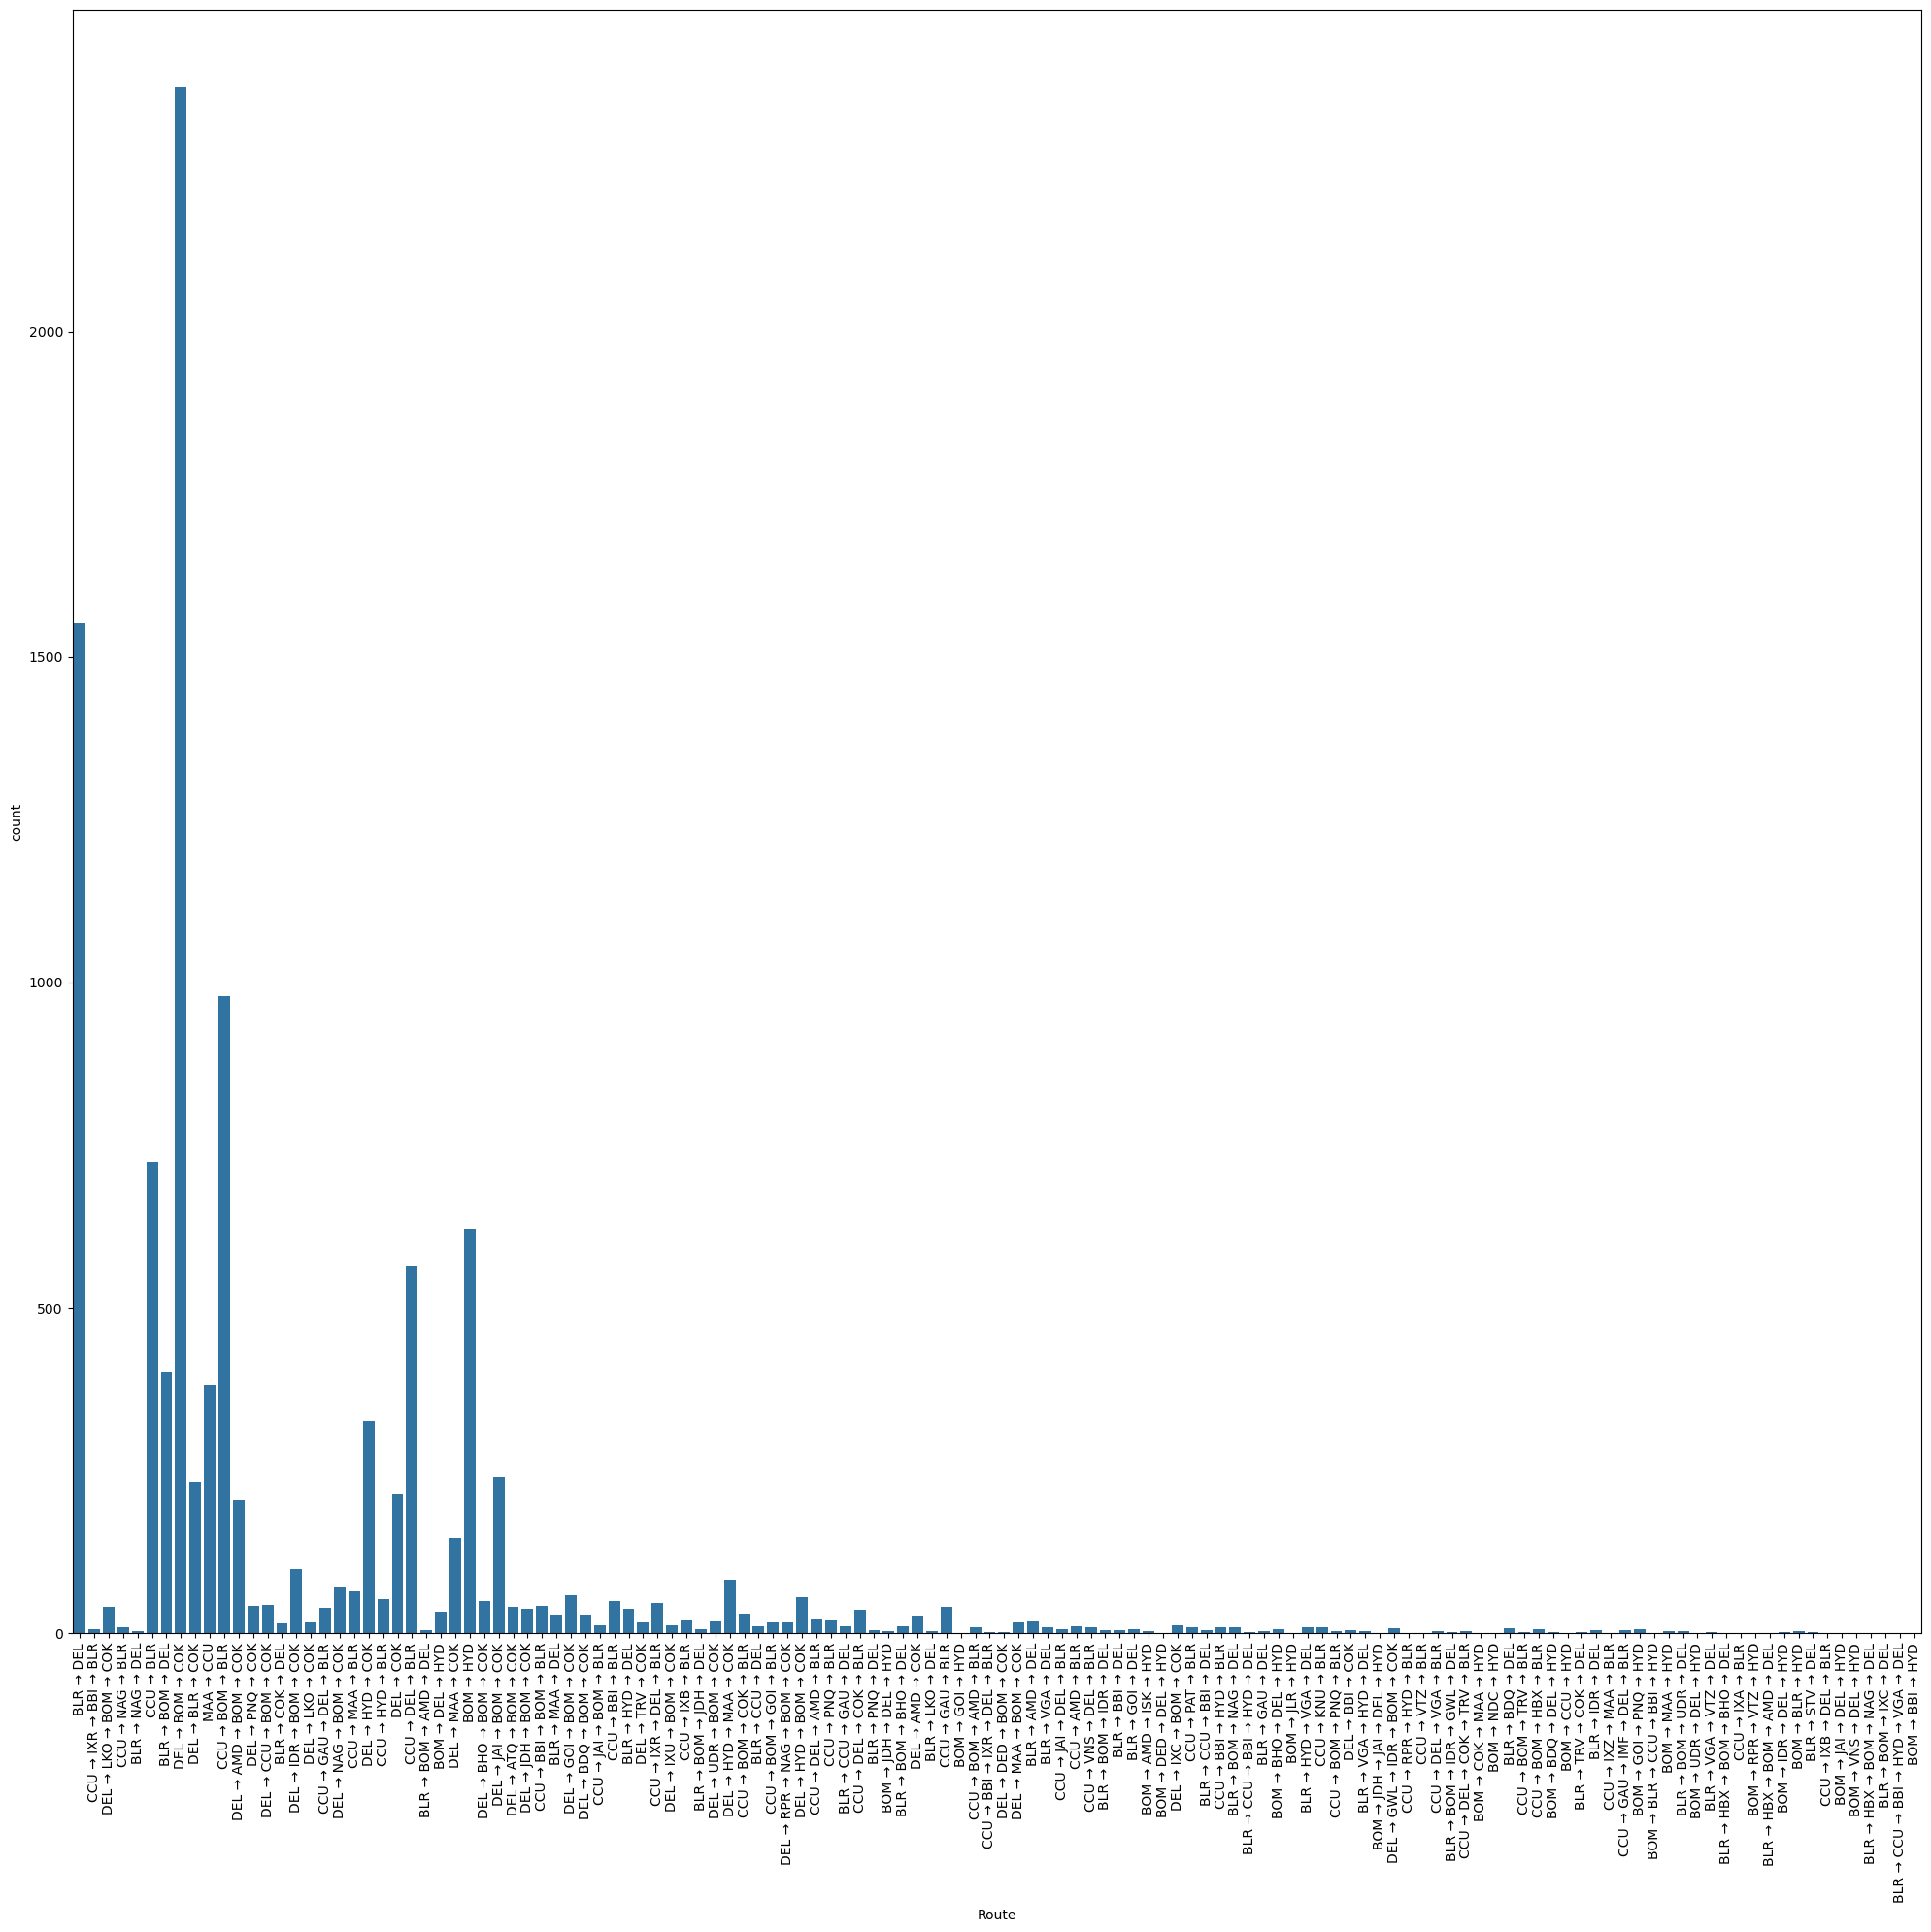

In [14]:
plt.figure(figsize=(20,20))  # Set the graph size
sns.countplot(x=df.Route)  # Count flights for each route
plt.xticks(fontsize=10, rotation=90)  # Rotate and set X-axis label size
plt.yticks(fontsize=10)  # Set Y-axis label size
plt.tight_layout()  # Adjust spacing to avoid overlap
plt.show()  # Display the graph

* Insights:
  * The graph shows which flight routes have the highest and lowest number of flights.

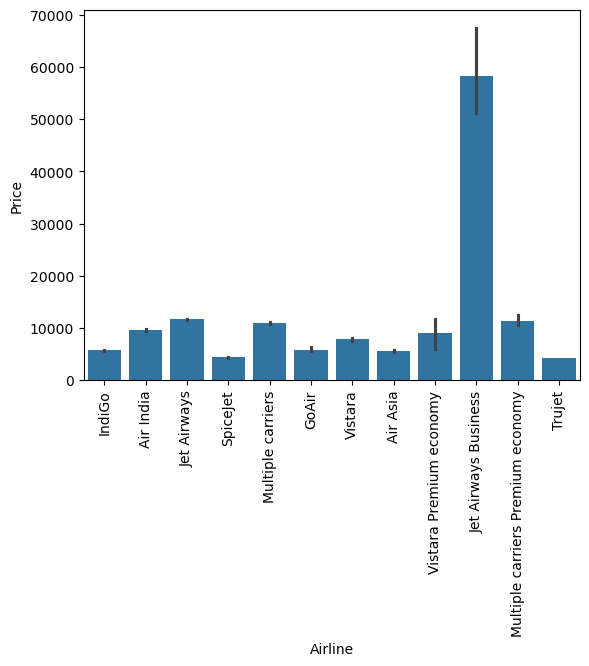

In [15]:
sns.barplot(x=df.Airline, y=df.Price)  # Compare average price by airline
plt.xticks(rotation=90)  # Rotate airline names for readability
plt.show()  # Display the graph

* Insights:
  * The graph compares the average flight price of each airline.

In [16]:
day_data = df[["Airline", "Date_of_Journey", "Price"]].copy()  # Select required columns and create a copy
day_data.head()  # Display the first 5 rows

,Airline,Date_of_Journey,Price
0,IndiGo,24/03/2019,3897
1,Air India,1/05/2019,7662
2,Jet Airways,9/06/2019,13882
3,IndiGo,12/05/2019,6218
4,IndiGo,01/03/2019,13302


In [17]:
day_data["Date_of_Journey"] = pd.to_datetime(day_data["Date_of_Journey"],format = "%d/%m/%Y")# Convert date into datetime format
day_data["Date_of_Journey"]  # Display journey dates
day_data["weekdays"] = day_data["Date_of_Journey"].dt.day_name()  # Get weekday names
day_data["weekdays"]  # Display weekday names
day_data["weekend"] = day_data["weekdays"].apply(lambda day: 1 if day == "Sunday" else 0)  # Mark Sunday as 1, other days as 0
day_data.head()  # Display first 5 rows

,Airline,Date_of_Journey,Price,weekdays,weekend
0,IndiGo,2019-03-24,3897,Sunday,1
1,Air India,2019-05-01,7662,Wednesday,0
2,Jet Airways,2019-06-09,13882,Sunday,1
3,IndiGo,2019-05-12,6218,Sunday,1
4,IndiGo,2019-03-01,13302,Friday,0


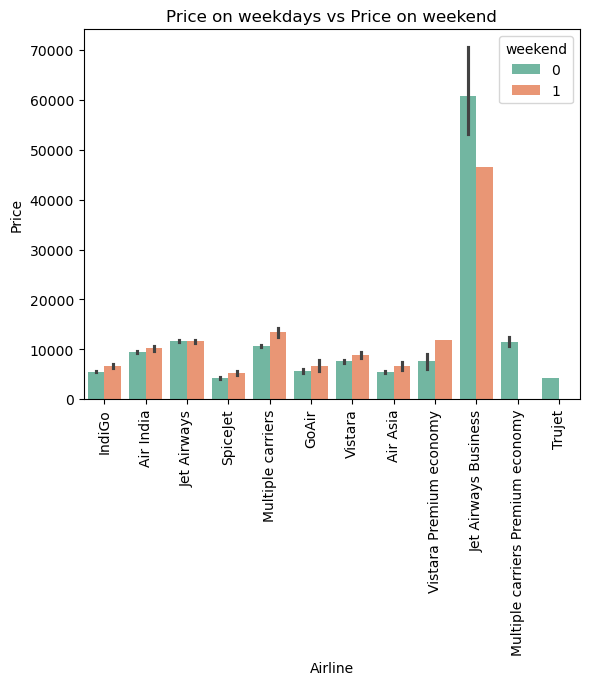

In [18]:
sns.barplot(x=df.Airline , y = df.Price , hue=day_data.weekend,palette="Set2")  # Compare average prices on weekdays vs Sunday
plt.title("Price on weekdays vs Price on weekend")  # Add chart title
plt.xticks(rotation=90)  # Rotate airline names for readability
plt.show()  # Display the graph

* Insights:
  * The graph compares airline prices on weekdays and weekends.

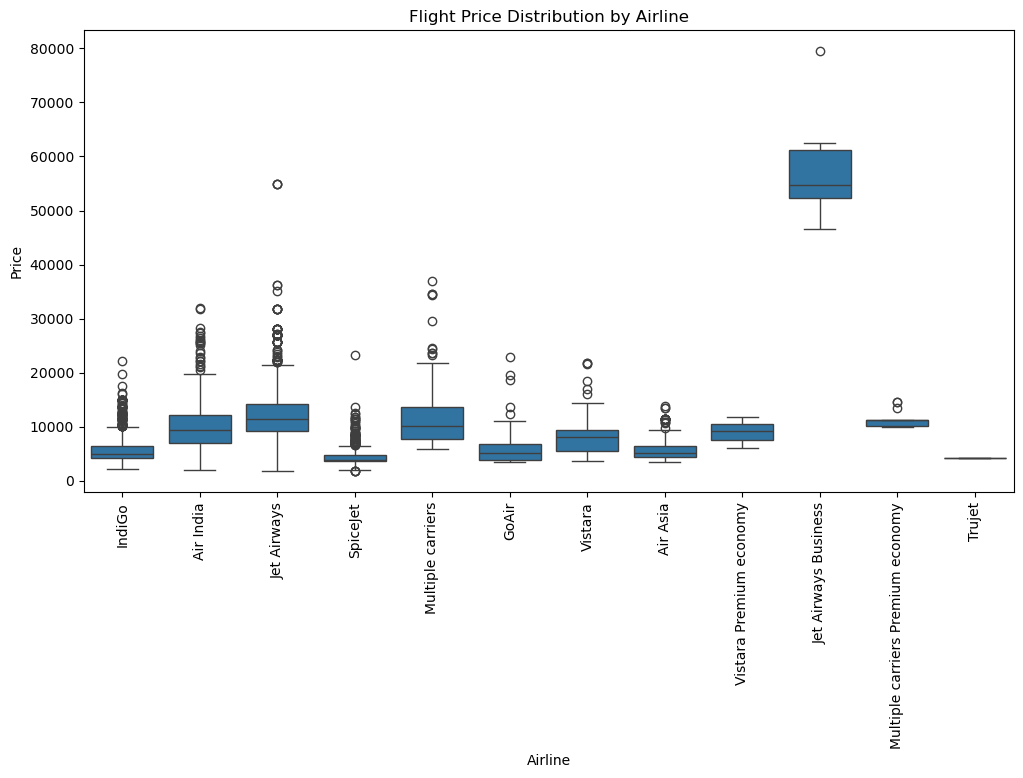

In [19]:
plt.figure(figsize=(12, 6))  # Set the graph size
sns.boxplot(x="Airline", y="Price", data=df) # show the outlier b/w two features
plt.xticks(rotation=90) # Rotate airline names for readability
plt.title("Flight Price Distribution by Airline")  # Add plot title
plt.xlabel("Airline") # set the X-axis name
plt.ylabel("Price") # set the  Y- axis name

plt.show() # Display the graph

### Insights:
* Some airlines show greater price variability than others.
* Several outliers indicate unusually high or low flight prices.


# Final Conclusion Of Insights:
* Delhi is a major flight destination/source, showing high flight activity.
* Most flights have 1 stop, making it the most common journey type.
* Flight prices are concentrated in a lower-to-middle range, with some higher-priced flights.
* Different airlines have different average prices, showing variation in airline pricing.
* Flight routes vary significantly, with some routes being much more frequently used.
* Flight prices also vary between weekdays and weekends across airlines.
* Therefore, Airline is an important feature for predicting flight prices.

# Feature Engineeeing:
1. Data Preprocessing
2. Data Engineeeing

1. Data Preprocessing

* Handling the missing values

In [20]:
df.head()  # Display the first 5 rows of the dataset

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [21]:
df.isnull().sum()  # Count missing values in each column

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [22]:
df.Route.mode()[0]  # Find the most frequent route

'DEL → BOM → COK'

In [23]:
df.loc[df["Route"].isnull(), "Route"] = "DEL → BOM → COK"  # Fill missing Route values

In [24]:
df.Total_Stops.mode()[0]  # Find the most common number of stops

'1 stop'

In [25]:
df.loc[df["Total_Stops"].isnull(), "Total_Stops"] = '1 stop'  # Fill missing stops

In [26]:
df.isnull().sum() # Count missing values in each column

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

* Cleaning the data

In [27]:
df["Journey_day"] = pd.to_datetime(df.Date_of_Journey, format="%d/%m/%Y").dt.day  # Extract journey day
df["Journey_month"] = pd.to_datetime(df.Date_of_Journey, format="%d/%m/%Y").dt.month  # Extract journey month

In [28]:
df.head(1)  # Display the first row of the dataset

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3


In [29]:
df["Dep_hours"] = pd.to_datetime(df.Dep_Time).dt.hour  # Extract departure hour
df["Dep_mins"] = pd.to_datetime(df.Dep_Time).dt.minute  # Extract departure minute

In [30]:
df.head(1)  # Display the first row of the dataset

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Dep_hours,Dep_mins
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20


In [31]:
df["Arrival_hours"] = pd.to_datetime(df.Arrival_Time).dt.hour  # Extract arrival hour
df["Arrival_mins"] = pd.to_datetime(df.Arrival_Time).dt.minute  # Extract arrival minute

In [32]:
df.head(1)  # Display the first row of the dataset

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Arrival_hours,Arrival_mins
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20,1,10


In [34]:
# Extract the hour value from the Duration column
df["Duration_hours"] = (
    df["Duration"]
    .str.extract(r"(\d+)h")[0]   # Extract the number before 'h'
    .fillna(0)                   # Replace missing hour values with 0
    .astype(int)                 # Convert the extracted values to integers
)

# Extract the minute value from the Duration column
df["Duration_mins"] = (
    df["Duration"]
    .str.extract(r"(\d+)m")[0]   # Extract the number before 'm'
    .fillna(0)                   # Replace missing minute values with 0
    .astype(int)                 # Convert the extracted values to integers
)

# Display the original duration along with the new hour and minute features
df[["Duration", "Duration_hours", "Duration_mins"]].head()

,Duration,Duration_hours,Duration_mins
0,2h 50m,2,50
1,7h 25m,7,25
2,19h,19,0
3,5h 25m,5,25
4,4h 45m,4,45


In [35]:
df.head(1)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Arrival_hours,Arrival_mins,Duration_hours,Duration_mins
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20,1,10,2,50


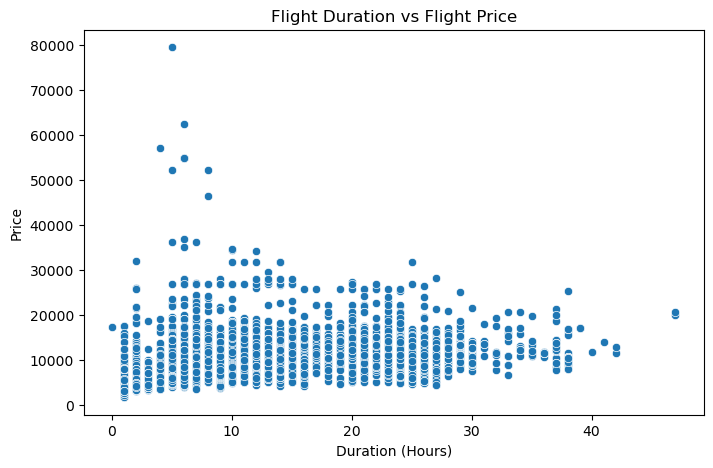

In [36]:
plt.figure(figsize=(8, 5)) # set the figure size
sns.scatterplot(x=df.Duration_hours,y=df.Price) #create a scatter plot of duration and price
plt.title("Flight Duration vs Flight Price") # add chart table
plt.xlabel("Duration (Hours)") #label the x-axis
plt.ylabel("Price") #label the Y-axis
plt.show()#Displau the plot

In [37]:
df.drop(["Date_of_Journey","Dep_Time","Arrival_Time","Duration","Additional_Info","Route"],axis=1,inplace=True)

In [38]:
df.head(1)  # Display the first row of the dataset

,Airline,Source,Destination,Total_Stops,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Arrival_hours,Arrival_mins,Duration_hours,Duration_mins
0,IndiGo,Banglore,New Delhi,non-stop,3897,24,3,22,20,1,10,2,50


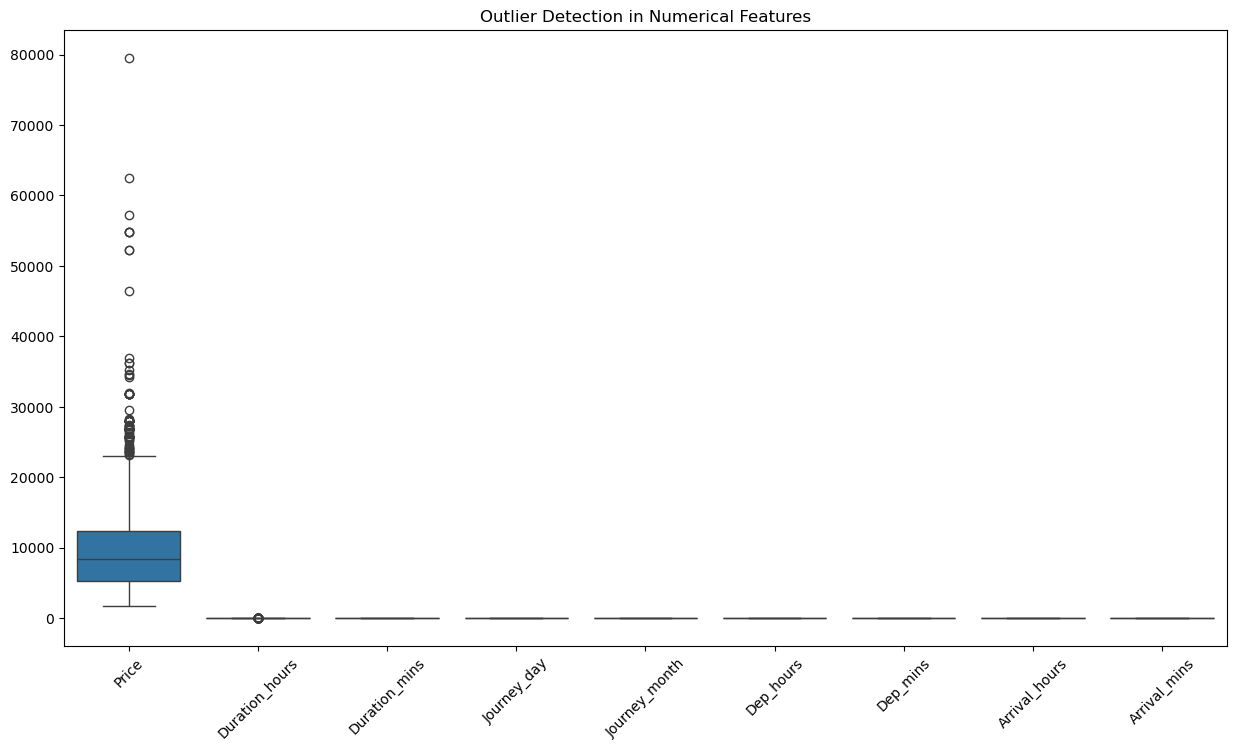

In [39]:
numerical_cols = [
    "Price",
    "Duration_hours",
    "Duration_mins",
    "Journey_day",
    "Journey_month",
    "Dep_hours",
    "Dep_mins",
    "Arrival_hours",
    "Arrival_mins"
] # Define the numerical columns for outlier detection
plt.figure(figsize=(15, 8)) # set the figure size
sns.boxplot(data=df[numerical_cols]) # Create box plots to detect outliers
plt.xticks(rotation=45) # Rotate X-axis labels forbetter readability
plt.title("Outlier Detection in Numerical Features") # Add chart title
plt.show() #Display the graph

### Insights:
* Some outliers are present in flight prices. Since these values may represent genuine high-priced flights, they were not removed from the dataset.”

* Convert Of Categorical Columns

In [40]:
df.Airline.value_counts()  # Count flights for each airline

Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1752
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

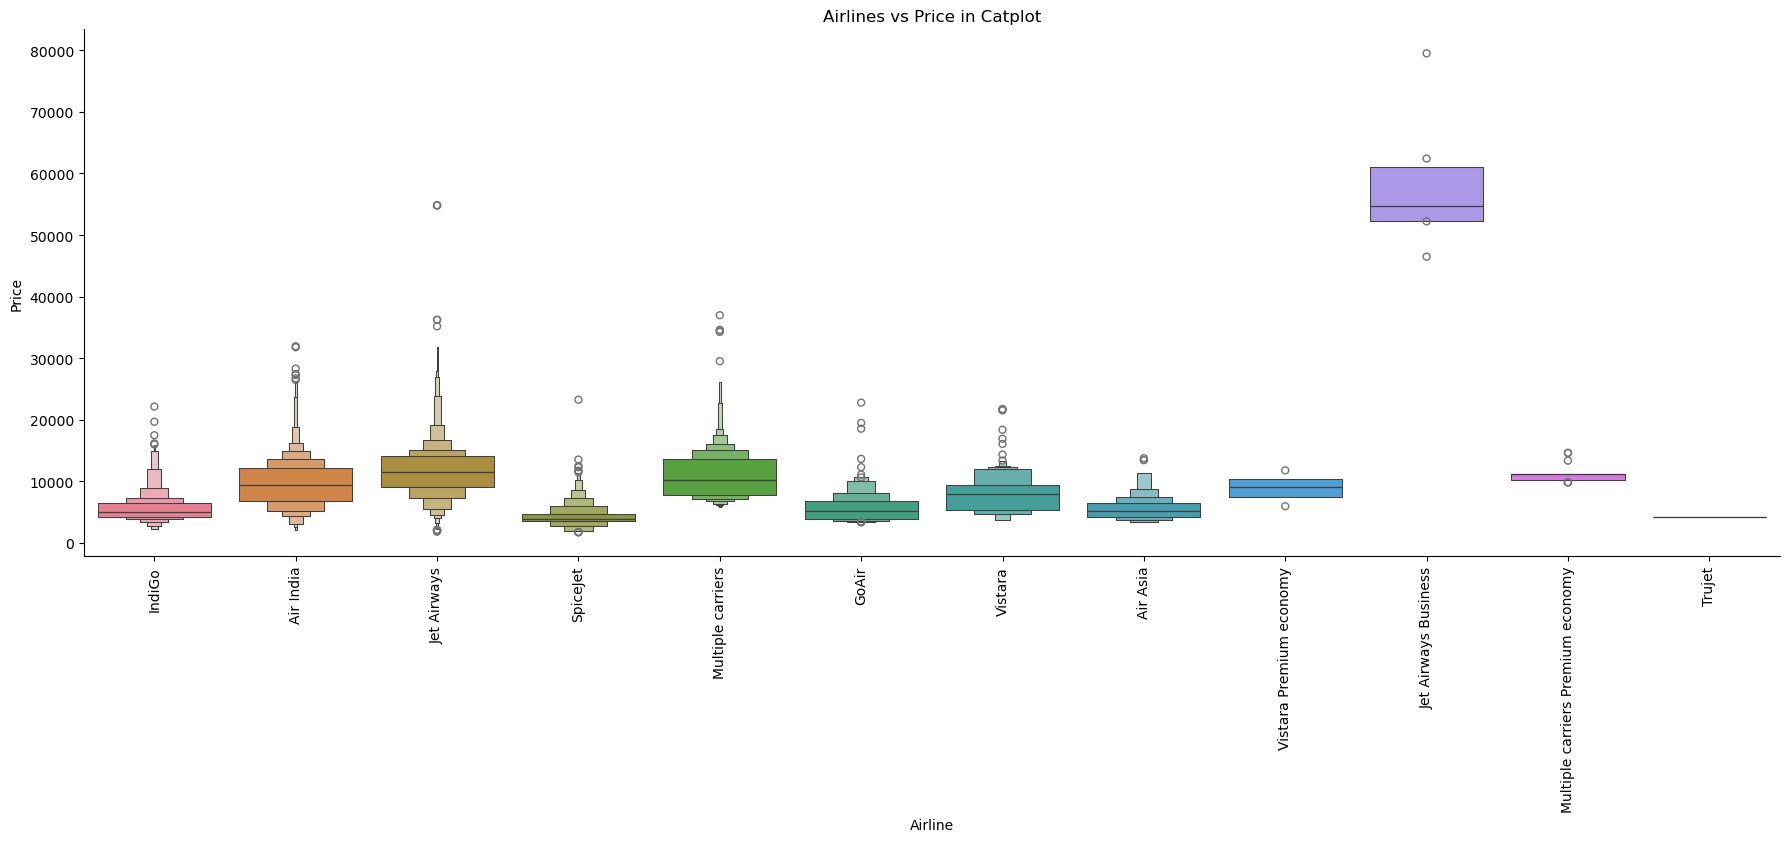

In [41]:
# here we can see Airline vs Price graphs
sns.catplot(y="Price",x="Airline",data=df.sort_values("Price",ascending=False),kind="boxen",height=6,aspect=3,hue=df.Airline)
plt.title("Airlines vs Price in Catplot")
plt.xticks(rotation=90)
plt.show()

* Insights:
  * Ticket prices vary across airlines, with some airlines showing a wider price range than others.

In [42]:
df.head(1)  # Display the first row of the dataset

,Airline,Source,Destination,Total_Stops,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Arrival_hours,Arrival_mins,Duration_hours,Duration_mins
0,IndiGo,Banglore,New Delhi,non-stop,3897,24,3,22,20,1,10,2,50


In [43]:
Airline = df[["Airline"]]  # Select the Airline column
Airline = pd.get_dummies(Airline, drop_first=True)  # Convert airlines into dummy variables
Airline.head()  # Display the first 5 rows

,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy
0,False,False,True,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,False
2,False,False,False,True,False,False,False,False,False,False,False
3,False,False,True,False,False,False,False,False,False,False,False
4,False,False,True,False,False,False,False,False,False,False,False


In [44]:
Source = df[["Source"]]  # Select the Source column
Source = pd.get_dummies(Source, drop_first=True)  # Convert source into dummy variables
Source.head()  # Display the first 5 rows

,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai
0,False,False,False,False
1,False,False,True,False
2,False,True,False,False
3,False,False,True,False
4,False,False,False,False


In [45]:
Destination = df[["Destination"]]  # Select the Destination column
Destination = pd.get_dummies(Destination, drop_first=True)  # Convert destinations into dummy variables
Destination.head()  # Display the first 5 rows

,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,False,False,False,False,True
1,False,False,False,False,False
2,True,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,True


In [46]:
df.Total_Stops.value_counts()  # Count flights for each number of stops

Total_Stops
1 stop      5626
non-stop    3491
2 stops     1520
3 stops       45
4 stops        1
Name: count, dtype: int64

In [47]:
df.Total_Stops = df.Total_Stops.replace({"non-stop":0,"1 stop":1,"2 stops":2,"3 stops":3,"4 stops":4}) # Convert stop categories to number

In [48]:
df.Total_Stops.head()  # Display the first 5 stop values

0    0
1    2
2    2
3    1
4    1
Name: Total_Stops, dtype: int64

In [49]:
df.head()  # Display the first 5 rows of the dataset

,Airline,Source,Destination,Total_Stops,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Arrival_hours,Arrival_mins,Duration_hours,Duration_mins
0,IndiGo,Banglore,New Delhi,0,3897,24,3,22,20,1,10,2,50
1,Air India,Kolkata,Banglore,2,7662,1,5,5,50,13,15,7,25
2,Jet Airways,Delhi,Cochin,2,13882,9,6,9,25,4,25,19,0
3,IndiGo,Kolkata,Banglore,1,6218,12,5,18,5,23,30,5,25
4,IndiGo,Banglore,New Delhi,1,13302,1,3,16,50,21,35,4,45


In [50]:
df = pd.concat([df, Airline, Source, Destination], axis=1)  # Combine all encoded columns with the dataset

In [51]:
df  # Display the complete dataset

,Airline,Source,Destination,Total_Stops,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Arrival_hours,Arrival_mins,Duration_hours,Duration_mins,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,IndiGo,Banglore,New Delhi,0,3897,24,3,22,20,1,10,2,50,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,Air India,Kolkata,Banglore,2,7662,1,5,5,50,13,15,7,25,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
2,Jet Airways,Delhi,Cochin,2,13882,9,6,9,25,4,25,19,0,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False
3,IndiGo,Kolkata,Banglore,1,6218,12,5,18,5,23,30,5,25,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
4,IndiGo,Banglore,New Delhi,1,13302,1,3,16,50,21,35,4,45,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,0,4107,9,4,19,55,22,25,2,30,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
10679,Air India,Kolkata,Banglore,0,4145,27,4,20,45,23,20,2,35,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
10680,Jet Airways,Banglore,Delhi,0,7229,27,4,8,20,11,20,3,0,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
10681,Vistara,Banglore,New Delhi,0,12648,1,3,11,30,14,10,2,40,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True


In [52]:
df.drop(["Airline", "Source", "Destination"], axis=1, inplace=True)  # Remove original categorical columns

In [53]:
df.head()  # Display the first 5 rows of the dataset

,Total_Stops,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Arrival_hours,Arrival_mins,Duration_hours,Duration_mins,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,3897,24,3,22,20,1,10,2,50,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,2,7662,1,5,5,50,13,15,7,25,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
2,2,13882,9,6,9,25,4,25,19,0,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False
3,1,6218,12,5,18,5,23,30,5,25,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
4,1,13302,1,3,16,50,21,35,4,45,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True


# Feature Selection:

In [54]:
df.corr() # Calculate correlation between numerical columns

,Total_Stops,Price,Journey_day,Journey_month,Dep_hours,Dep_mins,Arrival_hours,Arrival_mins,Duration_hours,Duration_mins,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
Total_Stops,1.000000,0.603883,-0.009472,0.054389,-0.061490,-0.002591,0.038123,-0.106939,0.739872,-0.136686,0.271084,-0.060113,-0.302998,0.215039,0.017876,0.118389,0.009088,-0.274356,0.002519,-0.120452,-0.020460,-0.234761,0.490166,0.032745,-0.260757,0.490166,-0.447394,-0.260757,-0.234761,-0.015310
Price,0.603883,1.000000,-0.153738,-0.103651,0.006819,-0.024492,0.024264,-0.086155,0.508672,-0.124874,0.050346,-0.095146,-0.361048,0.416135,0.253302,0.139803,0.017651,-0.296552,-0.010380,-0.060646,-0.000453,-0.179216,0.270619,0.009377,-0.230745,0.270619,-0.313401,-0.230745,-0.179216,0.189785
Journey_day,-0.009472,-0.153738,1.000000,-0.038378,0.002220,-0.008261,-0.003192,-0.017511,-0.022181,-0.008996,-0.032668,-0.003111,0.007322,-0.017241,-0.031710,0.042190,0.030841,0.022177,-0.008568,-0.013151,-0.020113,0.006626,0.099981,-0.060505,-0.014008,0.099981,0.002662,-0.014008,0.006626,-0.075225
Journey_month,0.054389,-0.103651,-0.038378,1.000000,0.039112,-0.059238,-0.003941,-0.100626,0.016175,-0.040880,-0.045917,-0.004497,-0.048515,0.059716,-0.034788,0.053676,-0.051223,-0.011984,-0.014199,-0.017257,-0.019797,0.005646,0.139240,0.087161,-0.039358,0.139240,0.090480,-0.039358,0.005646,-0.453689
Dep_hours,-0.061490,0.006819,0.002220,0.039112,1.000000,-0.024806,0.005215,0.067909,0.002783,-0.023746,-0.013004,-0.016365,-0.023367,0.113980,-0.007522,-0.149969,-0.028669,-0.010434,0.000857,0.023918,-0.003374,-0.014835,-0.118836,0.155500,-0.017277,-0.118836,0.009489,-0.017277,-0.014835,-0.022120
Dep_mins,-0.002591,-0.024492,-0.008261,-0.059238,-0.024806,1.000000,0.043054,-0.017594,-0.021946,0.092548,-0.045442,0.076733,-0.014763,0.024376,0.009165,-0.109400,-0.004628,0.092599,-0.010008,-0.077920,-0.011382,0.067086,-0.085405,-0.024298,0.037675,-0.085405,0.003162,0.037675,0.067086,0.107091
Arrival_hours,0.038123,0.024264,-0.003192,-0.003941,0.005215,0.043054,1.000000,-0.154362,0.055180,-0.118345,0.088716,0.018534,-0.071459,-0.027332,-0.014454,0.067949,0.013492,-0.090039,0.003740,0.068845,0.000777,-0.014783,-0.006859,0.054727,-0.033495,-0.006859,-0.030844,-0.033495,-0.014783,0.000384
Arrival_mins,-0.106939,-0.086155,-0.017511,-0.100626,0.067909,-0.017594,-0.154362,1.000000,-0.074439,0.151626,0.061220,0.096838,0.035123,-0.057698,0.005232,-0.167455,-0.001786,0.012542,-0.002750,0.069421,0.000314,-0.030493,-0.209867,0.118570,0.081196,-0.209867,0.095249,0.081196,-0.030493,0.021270
Duration_hours,0.739872,0.508672,-0.022181,0.016175,0.002783,-0.021946,0.055180,-0.074439,1.000000,-0.126355,0.261934,-0.094053,-0.346258,0.307050,-0.011849,-0.008119,-0.002275,-0.263855,-0.008253,-0.020387,-0.016269,-0.186675,0.299931,0.123424,-0.233338,0.299931,-0.346205,-0.233338,-0.186675,0.004008
Duration_mins,-0.136686,-0.124874,-0.008996,-0.040880,-0.023746,0.092548,-0.118345,0.151626,-0.126355,1.000000,-0.033273,0.067205,0.119781,-0.084097,-0.002324,-0.118786,-0.006855,0.041299,-0.007610,0.041937,0.004951,-0.098833,-0.154038,0.013722,-0.018777,-0.154038,0.218177,-0.018777,-0.098833,0.079844


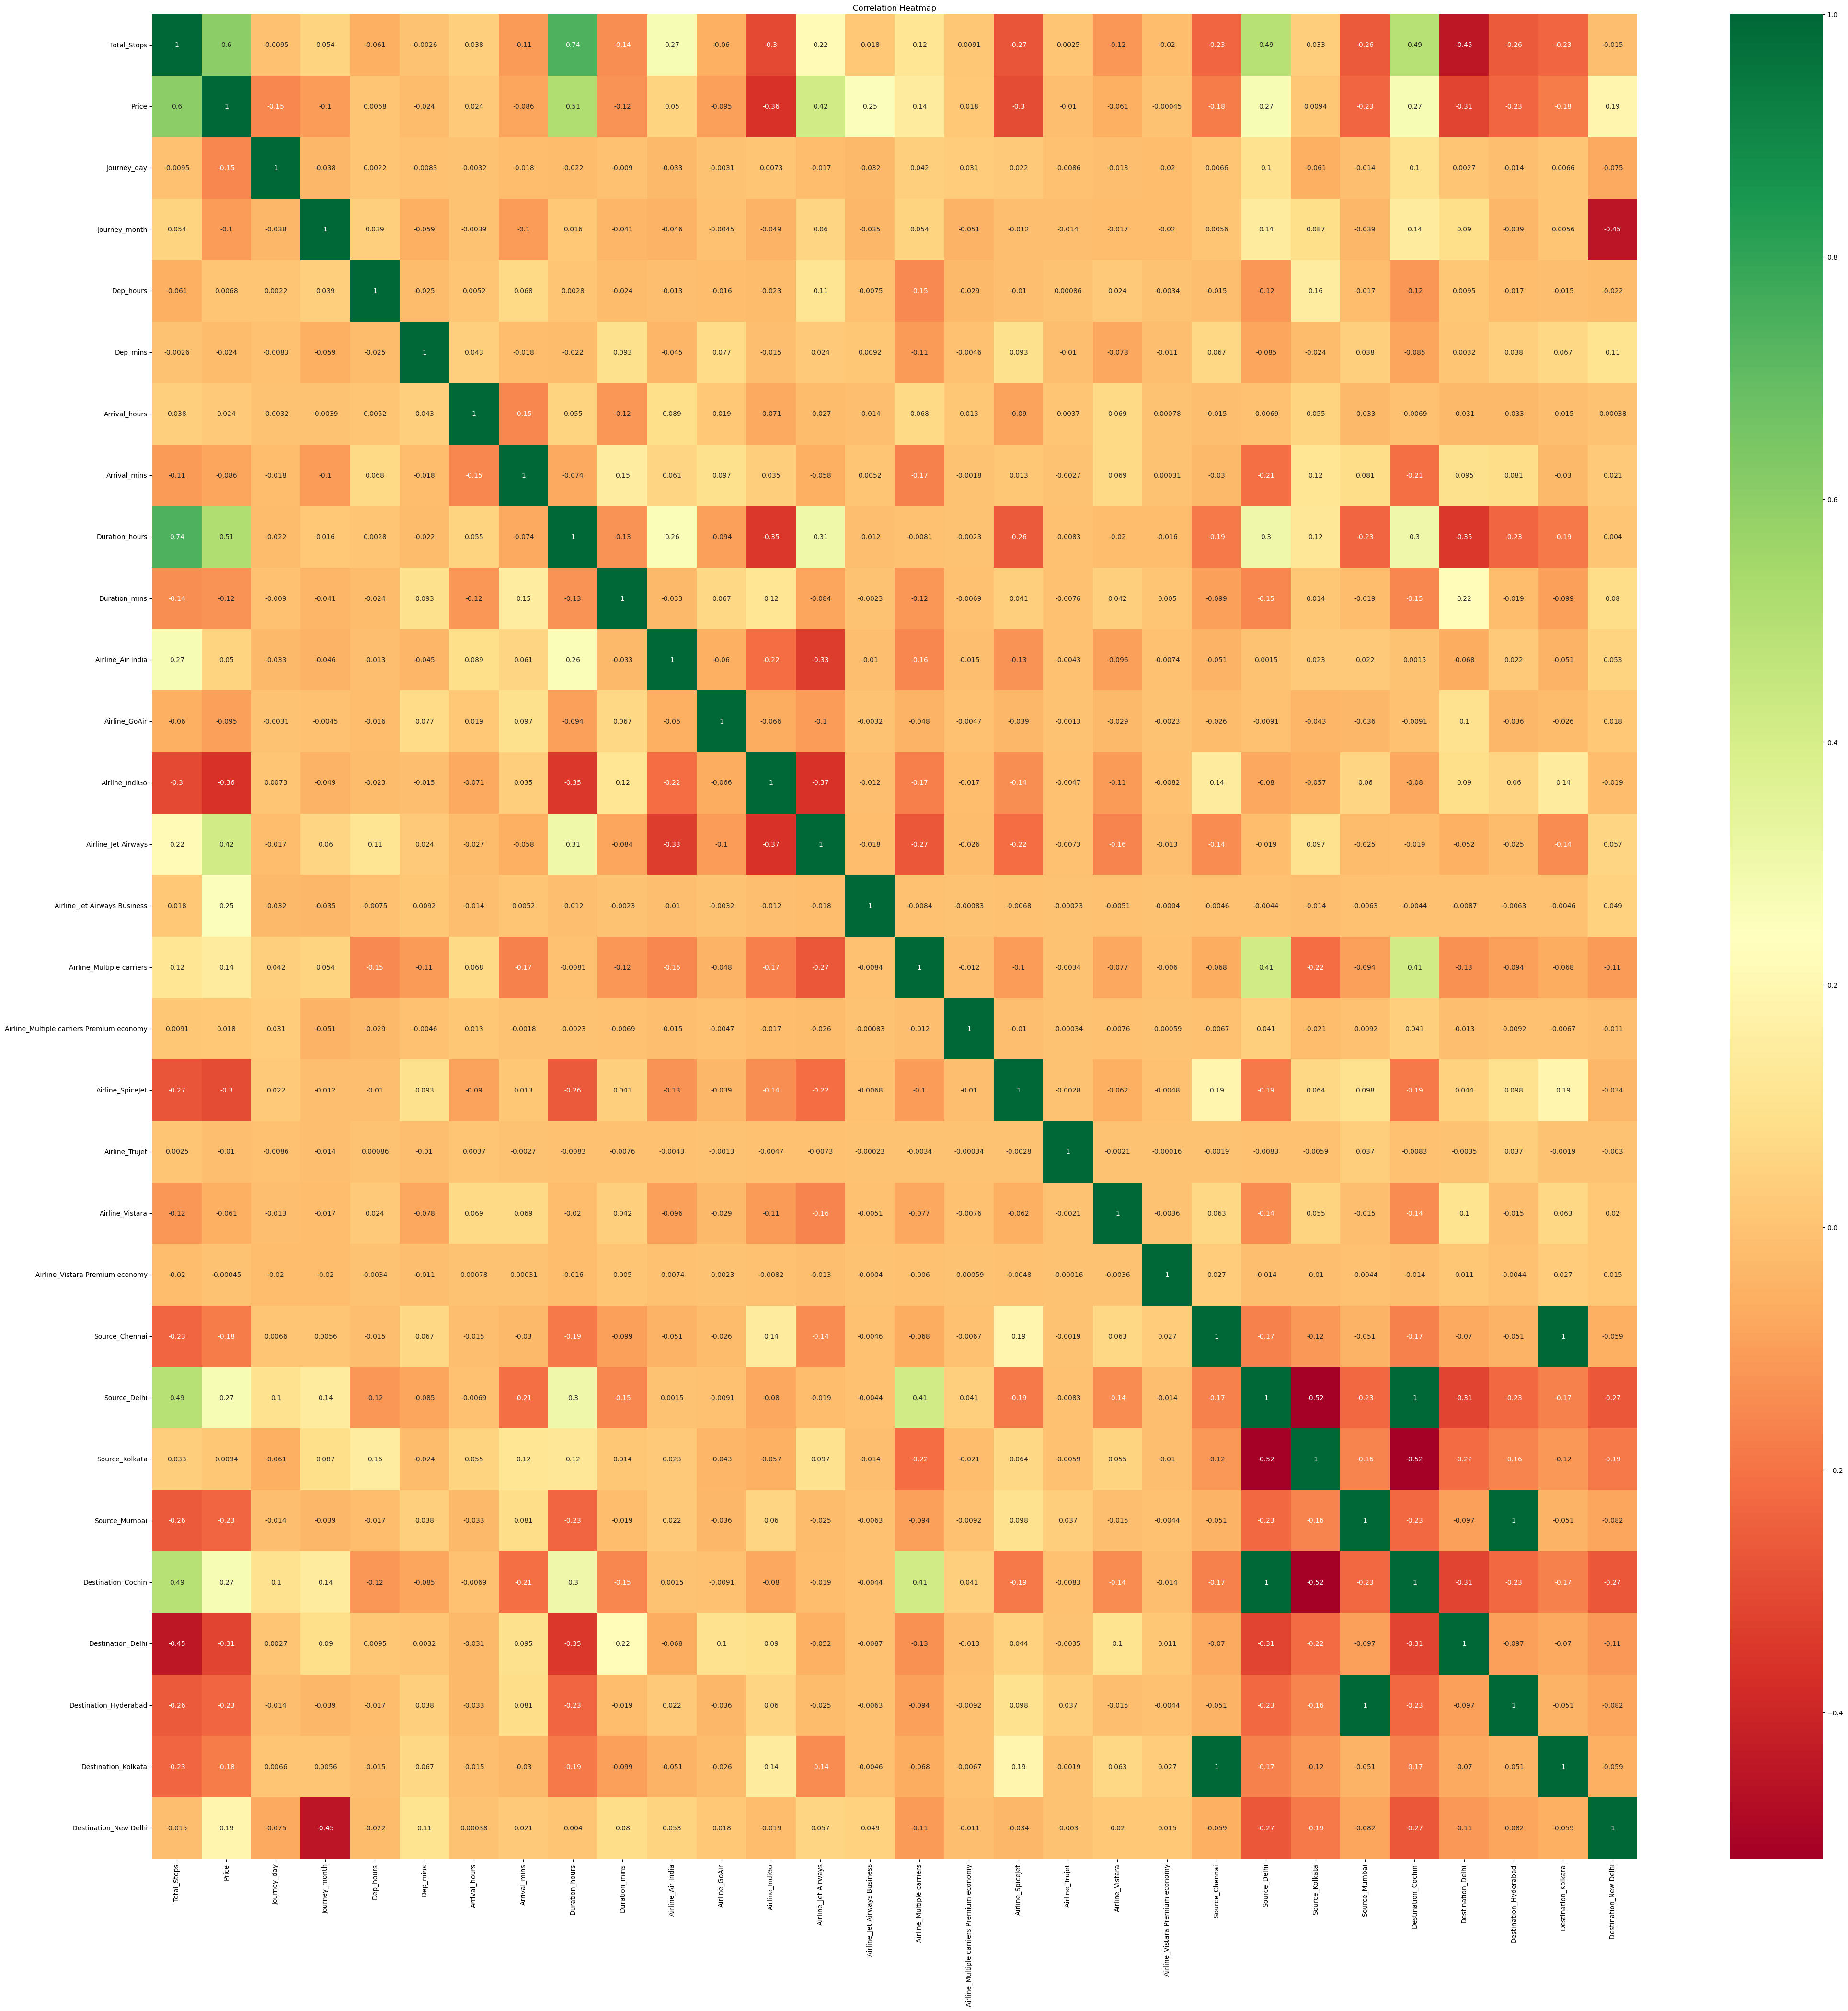

In [55]:
plt.figure(figsize=(50, 50))  # Set the figure size
sns.heatmap(df.corr(), annot=True, cmap="RdYlGn")  # Create correlation heatmap with values
plt.title("Correlation Heatmap")  # Add title
plt.show()  # Display the heatmap

* insights:
  * The heatmap shows the correlation between different numerical features.
  * Total_Stops has a noticeable relationship with Price, while many time-related features have weaker correlations.

### Create input and output variables.

In [56]:
x = df.drop("Price", axis=1)  # Remove Price column from input data
x  # Display the input variables

,Total_Stops,Journey_day,Journey_month,Dep_hours,Dep_mins,Arrival_hours,Arrival_mins,Duration_hours,Duration_mins,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,24,3,22,20,1,10,2,50,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,2,1,5,5,50,13,15,7,25,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
2,2,9,6,9,25,4,25,19,0,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False
3,1,12,5,18,5,23,30,5,25,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
4,1,1,3,16,50,21,35,4,45,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,0,9,4,19,55,22,25,2,30,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
10679,0,27,4,20,45,23,20,2,35,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
10680,0,27,4,8,20,11,20,3,0,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
10681,0,1,3,11,30,14,10,2,40,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True


In [57]:
y = df.Price  # Select Price as the output variable
y  # Display the target values

0         3897
1         7662
2        13882
3         6218
4        13302
         ...  
10678     4107
10679     4145
10680     7229
10681    12648
10682    11753
Name: Price, Length: 10683, dtype: int64

# Model Selection :

In [58]:
from sklearn.model_selection import train_test_split  # Import function to split data

In [59]:
X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size=0.20, random_state=33)  # Split data into train and test sets

# Model Creation :

### 1. Linear Regression 

In [60]:
from sklearn.linear_model import LinearRegression  # Import Linear Regression model

In [61]:
LR = LinearRegression()  # Create a Linear Regression model

In [62]:
LR.fit(X_train,Y_train)  # Train the model using training data

LinearRegression()

In [63]:
y_pred = LR.predict(X_test)  # Predict prices for test data
y_pred  # Display predicted prices

array([11391.8793277 , 11147.04872162, 13030.50097101, ...,
       14741.74125824,  8987.64357197,  4677.64342138])

In [64]:
Y_test.values  # Display actual test values

array([10844, 10975, 12819, ..., 11664,  7532,  3971])

# Model Evalution Of LinearRegression

In [65]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error  # Import evaluation metrics

In [151]:
r2score = r2_score(Y_test, y_pred)  # Calculate R² score
r2score  # Display the R² score

0.612034652283074

In [67]:
print(mean_squared_error(Y_test, y_pred))  # Print MSE
print(mean_absolute_error(Y_test, y_pred))  # Print MAE
print(root_mean_squared_error(Y_test, y_pred))  # Print RMSE
mse = mean_squared_error(Y_test, y_pred)  # Store MSE value
mse  # Display MSE

8950777.21726268
1968.3925310331038
2991.7849550498577


8950777.21726268

# KNN

In [72]:
from sklearn.preprocessing import MinMaxScaler  # Import Min-Max scaler
scaler = MinMaxScaler()  # Create the scaler
X_train_scaled = scaler.fit_transform(X_train) # Fit the scaler on training data and scale it
X_test_scaled = scaler.transform(X_test) # Scale the test data using the same training-data scaler

In [73]:
# KNN will use the scaled training and testing data
X_train_scaled.shape, X_test_scaled.shape

((8546, 29), (2137, 29))

In [74]:
from sklearn.neighbors import KNeighborsRegressor  # Import KNN regression model
KNN = KNeighborsRegressor(n_neighbors=3, weights="distance")  # Create KNN model

In [75]:
KNN.fit(X_train_scaled, Y_train)  # Train the model using training data

KNeighborsRegressor(n_neighbors=3, weights='distance')

In [77]:
Y_pred2 = KNN.predict(X_test_scaled) # predict the testing data
Y_pred2 # Predict prices using KNN

array([10097.67869   ,  9353.13891957, 11706.33333333, ...,
       14487.72830501,  7027.04469277,  3919.        ])

# Model Evalution Of KNN

In [78]:
r2_score1 = r2_score(Y_test, Y_pred2)  # Calculate KNN R² score
r2_score1  # Display R² score

0.6512343134431147

In [79]:
mse1 = mean_squared_error(Y_test, Y_pred2)  # Calculate KNN MSE
mse1  # Display MSE

8046398.936829977

### DecisionTreeRegressor

In [80]:
from sklearn.tree import DecisionTreeRegressor  # Import Decision Tree regression model

In [81]:
dr = DecisionTreeRegressor(random_state=69)  # Create Decision Tree model

In [82]:
dr.fit(X_train,Y_train)  # Train the model using training data

DecisionTreeRegressor(random_state=69)

In [83]:
dr_pred = dr.predict(X_test)  # Predict prices using Decision Tree
dr_pred  # Display predicted prices

array([ 9663.  , 10975.  , 11567.25, ..., 10909.  ,  5957.  ,  3919.  ])

### Model Evalution Of DecisionTree Regressor

In [84]:
r2_score2 = r2_score(Y_test, dr_pred)  # Calculate Decision Tree R² score
r2_score2  # Display R² score

0.7407301897873454

In [85]:
print(mean_squared_error(Y_test, dr_pred))  # Print MSE
print(mean_absolute_error(Y_test, dr_pred))  # Print MAE

5981632.957767899
1295.8317735142723


In [86]:
mse2 = mean_squared_error(Y_test, dr_pred)  # Calculate Decision Tree MSE
mse2  # Display MSE

5981632.957767899

### DecisionTreeRegressor with Hyperperameter Tunning

In [87]:
from sklearn.model_selection import GridSearchCV  # Import Grid Search

In [88]:
params = {"splitter":("best","random"),
         "max_depth":(list(range(1,20))),
         "min_samples_split":[2,3,4],
         "min_samples_leaf":(list(range(1,20))),
         "max_leaf_nodes":[None,10,20,30,40,50,60,70,80,90]}  # Set parameters to test
tree_clf = DecisionTreeRegressor(random_state=3)  # Create Decision Tree model
tree_cv = GridSearchCV(tree_clf, params, scoring="r2", n_jobs=-1, verbose=1, cv=3)  # Set up Grid Search
tree_cv.fit(X_train, Y_train) # Train the model using training data
best_params = tree_cv.best_params_  # Get the best parameters
print(f"Best parameters: {best_params}")  # Display best parameters

Fitting 3 folds for each of 21660 candidates, totalling 64980 fits
Best parameters: {'max_depth': 13, 'max_leaf_nodes': None, 'min_samples_leaf': 3, 'min_samples_split': 2, 'splitter': 'random'}


In [89]:
Bestparamters: ({'max_depth': 12, 'min_samples_leaf': 1, 'min_samples_split': 3, 'splitter': 'random',"max_leaf_nodes":None})
tree_cv.best_params_ #getting best parameters from cv    

{'max_depth': 13,
 'max_leaf_nodes': None,
 'min_samples_leaf': 3,
 'min_samples_split': 2,
 'splitter': 'random'}

In [90]:
dt1 = DecisionTreeRegressor(max_depth=12,max_leaf_nodes= None,min_samples_leaf= 1,min_samples_split=3,splitter='random',random_state=47)
# Create optimized Decision Tree model

In [91]:
dt1.fit(X_train,Y_train) # Train the model using training data

DecisionTreeRegressor(max_depth=12, min_samples_split=3, random_state=47,
                      splitter='random')

In [92]:
y_hat1 = dt1.predict(X_test)  # Predict prices using tuned Decision Tree
y_hat1  # Display predicted prices

array([10790.02631579, 11771.76      , 12151.4       , ...,
       11227.5       ,  6779.76229508,  4126.54081633])

In [93]:
par = r2_score(Y_test, y_hat1)  # Calculate R² score
par  # Display R² score

0.7773813810504842

### RandomForestRegressor

In [94]:
from sklearn.ensemble import RandomForestRegressor  # Import Random Forest regression model

In [96]:
rf = RandomForestRegressor(n_estimators=101,random_state=99) # Create a Random Forest Regressor with 101 decision trees

In [97]:
rf.fit(X_train,Y_train)  # Train the model using training data

RandomForestRegressor(n_estimators=101, random_state=99)

In [99]:
rf_pred = rf.predict(X_test) # Predict flight prices for the test data
rf_pred # Display the predict price

array([10761.13613861, 10889.34653465, 11548.83670438, ...,
       11537.53960396,  6491.38613861,  3897.58415842])

# Model Evalution Of RandomForestRegressor

In [100]:
r2_score3 = r2_score(Y_test,rf_pred) # Calculate R² score for the Random Forest model
r2_score3 # Display the R2 score

0.8388319986251792

In [102]:
mse3 = mean_squared_error(Y_test,rf_pred) # Calculate Mean Squared Error (MSE)
mse3 # Display the MSE

3718318.8739579543

### RandomForestRegressor with Hyperparameters Tunning

In [103]:
from sklearn.model_selection import RandomizedSearchCV # Create Random Forest model

In [104]:
n_estimators = [int(x) for x in np.linspace(start=200, stop=2000 , num=10)]  # Set number of trees
max_features = ['auto','sqrt'] # Set feature selection options
max_depth = [int(x) for x in np.linspace(10,110,num=11)] # Set tree depth options
max_depth.append(None)  # Allow unlimited depth
min_samples_split = [2,5,10]# Set minimum samples for splitting
min_samples_leaf = [1, 2, 4]  # Set minimum samples in each leaf
bootstrap = [True, False]  # Set bootstrap sampling options

random_grid = {'n_estimators':n_estimators,'max_features':max_features,'max_depth':max_depth,
               'min_samples_split':min_samples_split,'min_samples_leaf':min_samples_leaf,'bootstrap':bootstrap} # Create parameter grid
rf_clf1 = RandomForestRegressor(random_state=42)  # Create Random Forest model
rf_cv = RandomizedSearchCV(estimator=rf_clf1, scoring="r2",param_distributions=random_grid,n_iter=100,cv=3,
                          verbose=2,random_state=42,n_jobs=-1) # Set up Randomized Search
rf_cv.fit(X_train,Y_train)  # Train the model using training data
rf_best_params = rf_cv.best_params_ # Get the best parameters
print(f"Best paramters:{rf_best_params})") # Display best parameters

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best paramters:{'n_estimators': 600, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 40, 'bootstrap': False})


In [105]:
rf_cv.best_params_  # Display the best Random Forest parameters

{'n_estimators': 600,
 'min_samples_split': 10,
 'min_samples_leaf': 1,
 'max_features': 'sqrt',
 'max_depth': 40,
 'bootstrap': False}

In [106]:
rf_cv.best_score_ # Display the best cross-validation R² score

np.float64(0.8079072195079103)

In [107]:
rf1 = RandomForestRegressor(n_estimators=1000,min_samples_leaf=1,min_samples_split=10,max_features="sqrt",max_depth=80,
                           bootstrap=False,random_state=99)  # Create tuned Random Forest model

In [108]:
rf1.fit(X_train,Y_train)  # Train the model using training data

RandomForestRegressor(bootstrap=False, max_depth=80, max_features='sqrt',
                      min_samples_split=10, n_estimators=1000, random_state=99)

In [109]:
y_rf_random = rf1.predict(X_test)  # Predict prices using tuned Random Forest
y_rf_random  # Display predicted prices

array([10632.58297222, 10668.33110833, 12210.55865079, ...,
       11981.8326996 ,  8059.12015317,  3886.10657897])

In [110]:
par1 = r2_score(Y_test, y_rf_random)  # Calculate Random Forest R² score
par1  # Display R² score

0.8189392603772901

### XGBoost

In [111]:
!pip install xgboost  # Install the XGBoost library

ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


In [112]:
import xgboost as xg  # Import XGBoost library
from xgboost import XGBRegressor  # Import XGBoost regression model

In [113]:
xgb_r = xg.XGBRegressor(objective='reg:linear',n_estimators=90,seed=123) # Create XGBoost regression model

In [114]:
xgb_r.fit(X_train,Y_train)  # Train the model using training data

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=90,
             n_jobs=None, num_parallel_tree=None, ...)

In [115]:
xgb_pred = xgb_r.predict(X_test)  # Predict prices using XGBoost
xgb_pred  # Display predicted prices

array([10781.5625, 10708.9   , 12190.327 , ..., 10187.178 ,  7334.4844,
        4012.935 ], dtype=float32)

# Model Evalution Of XGBoost

In [116]:
r2_score4 = r2_score(Y_test, xgb_pred)  # Calculate XGBoost R² score
r2_score4  # Display R² score

0.8512054681777954

In [117]:
mse4 = mean_squared_error(Y_test, xgb_pred)  # Calculate XGBoost MSE
mse4  # Display MSE

3432849.75

### XGBoost with Hyperperameter Tunning

In [118]:
param_grid = {'gamma': [0,0.1,0.2,0.4,0.8,1.6,3.2,6.4,12.8,25.6,51.2,102.4, 200],
              'learning_rate': [0.01, 0.03, 0.06, 0.1, 0.15, 0.2, 0.25, 0.300000012, 0.4, 0.5, 0.6, 0.7],
              'max_depth': [5,6,7,8,9,10,11,12,13,14],#max depth of XGBRegressor
              'n_estimators': [50,65,80,100,115,130,150],#assign n_estimator number of samples required to split 
              'reg_alpha': [0,0.1,0.2,0.4,0.8,1.6,3.2,6.4,12.8,25.6,51.2,102.4,200],#assign reg_alpha number of samples required to split 
              'reg_lambda': [0,0.1,0.2,0.4,0.8,1.6,3.2,6.4,12.8,25.6,51.2,102.4,200]}#assign reg_lambda number of samples required to split 

In [119]:
XGB = xg.XGBRegressor(random_state=42,verbosity=0,silent=0) # Create XGBoost model
rcv = RandomizedSearchCV(estimator=XGB,scoring='r2',param_distributions=param_grid,n_iter=100,cv=5,verbose=2,n_jobs=-1) # Set up randomized parameter search

In [120]:
rcv.fit(X_train,Y_train)  # Train the model using training data

Fitting 5 folds for each of 100 candidates, totalling 500 fits


RandomizedSearchCV(cv=5,
                   estimator=XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=None, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=True,
                                          eval_metric=None, feature_types=None,
                                          feature_weights=None, gamma=None,
                                          grow_policy=None,
                                          importance_type=None,
                                          interaction_constraints...
                                                  3.2, 6.4, 12.8, 25.6, 51.2,
                                                  102.4, 200],
                                        'learning_rate': [0.01, 0.03, 0.06, 0.1,
                                                          0.15, 0.2, 0.25,
                                                          0.300000012, 0.4, 0.5,
                                                          0.6, 0.7],
                                        'max_depth': [5, 6, 7, 8, 9, 10, 11, 12,
                                                      13, 14],
                                        'n_estimators': [50, 65, 80, 100, 115,
                                                         130, 150],
                                        'reg_alpha': [0, 0.1, 0.2, 0.4, 0.8,
                                                      1.6, 3.2, 6.4, 12.8, 25.6,
                                                      51.2, 102.4, 200],
                                        'reg_lambda': [0, 0.1, 0.2, 0.4, 0.8,
                                                       1.6, 3.2, 6.4, 12.8,
                                                       25.6, 51.2, 102.4,
                                                       200]},
                   scoring='r2', verbose=2)

In [121]:
cv_best_params = rcv.best_params_  # Get the best XGBoost parameters
print(f"Best parameter: {cv_best_params}")  # Display best parameters

Best parameter: {'reg_lambda': 12.8, 'reg_alpha': 0.2, 'n_estimators': 115, 'max_depth': 6, 'learning_rate': 0.4, 'gamma': 12.8}


In [122]:
XGB2 =xg.XGBRegressor(reg_lambda = 12.8, reg_alpha = 6.4, n_estimators= 150, max_depth= 7, learning_rate = 0.15, gamma= 0.8)# Create tuned XGBoost model

In [123]:
XGB2.fit(X_train,Y_train)  # Train the model using training data

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=0.8, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.15, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=150,
             n_jobs=None, num_parallel_tree=None, ...)

In [124]:
y_predictxgb = XGB2.predict(X_test)  # Predict test data prices
x_predictxgb = XGB2.predict(X_train)  # Predict train data prices

In [125]:
print("Train r2_score : ", r2_score(Y_train, x_predictxgb))  # Print train R²
print("Test r2_score : ", r2_score(Y_test, y_predictxgb))  # Print test R²
r2 = r2_score(Y_test, y_predictxgb)  # Store test R² score
r2  # Display test R²

Train r2_score :  0.9065172672271729
Test r2_score :  0.8529554009437561


0.8529554009437561

In [132]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": XGB2.feature_importances_}) # Create a DataFrame containing feature names and their importance
feature_importance = feature_importance.sort_values(by="Importance",ascending=False)# Sort features from highest to lowest importance

feature_importance # Display the feature importance table

,Feature,Importance
7,Duration_hours,0.225803
12,Airline_Jet Airways,0.168558
13,Airline_Jet Airways Business,0.120883
11,Airline_IndiGo,0.078898
28,Destination_New Delhi,0.076725
14,Airline_Multiple carriers,0.048341
1,Journey_day,0.043632
0,Total_Stops,0.042171
2,Journey_month,0.026644
22,Source_Kolkata,0.024915


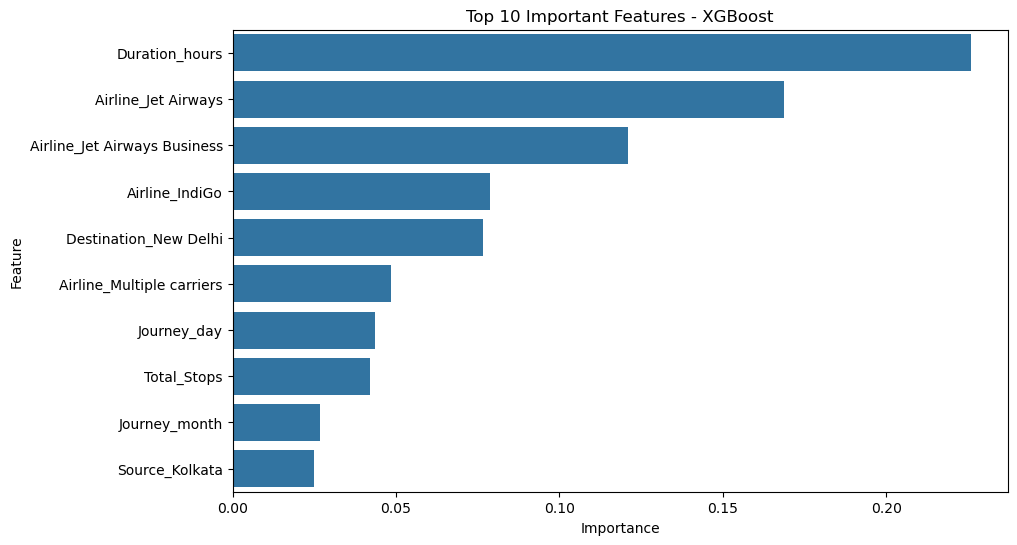

In [133]:
plt.figure(figsize=(10, 6)) # set the figure size

sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance.head(10)
) # Plot the top 10 important features

plt.title("Top 10 Important Features - XGBoost") # Add chart title
plt.xlabel("Importance") # Label the X-axis
plt.ylabel("Feature") # Label the Y-axis
plt.show() # Display the plot

### Insights:
* The bar plot shows the top 10 features that contribute most to the XGBoost model’s predictions.”

### ARTIFICIAL NEURAL NETWORK

In [134]:
from sklearn.neural_network import MLPRegressor  # Import neural network regression model

In [135]:
model = MLPRegressor(hidden_layer_sizes=(150, 3), learning_rate_init=0.1, max_iter=500, random_state=33)  # Create neural network model

In [136]:
model.fit(X_train_scaled, Y_train)  # Train the model using training data

MLPRegressor(hidden_layer_sizes=(150, 3), learning_rate_init=0.1, max_iter=500,
             random_state=33)

In [137]:
y_predict_proba = model.predict(X_test_scaled) # Predict values for the test data using the trained ANN model
y_train_predict = model.predict(X_train_scaled) # Predict values for the training data

In [138]:
print(y_predict_proba)  # Display test predictions
print(y_train_predict)  # Display train predictions

[11188.05574036  9748.72012499 15157.01915743 ... 12609.18154009
  6493.28756915  3922.15644893]
[ 5750.3962057   4628.89785389  8590.80279903 ... 12882.49647515
  8473.89899577 11594.15729594]


# Model Evalution Of ANN


In [140]:
print("Train r2 Score:", r2_score(Y_train, y_train_predict))  # Print train R²
print("Test r2 Score:", r2_score(Y_test, y_predict_proba))  # Print test R²

Train r2 Score: 0.7760237556909806
Test r2 Score: 0.7537304930657907


In [141]:
r2_score5 = r2_score(Y_test, y_predict_proba)  # Calculate neural network R²
r2_score5  # Display R² score

0.7537304930657907

In [142]:
mse5 = mean_squared_error(Y_test, y_predict_proba)  # Calculate MLP MSE
mse5  # Display MSE

5681701.999791941

In [143]:
from sklearn.model_selection import KFold, cross_val_score # Import KFold and cross-validation functions
from sklearn.pipeline import Pipeline  # Import Pipeline for combining preprocessing and model

ann_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model", MLPRegressor(
        hidden_layer_sizes=(150, 3),
        learning_rate_init=0.1,
        max_iter=500,
        random_state=33
    ))
]) # Create a pipeline for scaling and ANN model

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=33
) # Create 5-fold cross-validation

ann_cv_scores = cross_val_score(
    ann_pipeline,
    x,
    y,
    cv=kf,
    scoring="r2"
) # Evaluate the ANN using 5-fold cross-validation

print("ANN Cross Validation R2 Scores:", ann_cv_scores) # Display R2 score for each fold
print("Mean ANN CV R2 Score:", ann_cv_scores.mean())  # Display the average R2 score

ANN Cross Validation R2 Scores: [0.77092315 0.76538876 0.77463906 0.73989772 0.75865591]
Mean ANN CV R2 Score: 0.7619009190649086


# Model Comparison Report

In [160]:
# Create model comparison table
score = pd.DataFrame({
    "MODEL": [
        "LinearRegression",
        "KNN",
        "DecisionTreeRegressor",
        "RandomForestRegressor",
        "XGBRegressor",
        "ANN_MLPRegressor"
    ],

    "R2_SCORE": [
        r2score*100,
        r2_score1*100,
        r2_score2*100,
        r2_score3*100,
        r2_score4*100,
        r2_score5*100
    ],

    "With Hyperparameter Tuning": [
        "No Available",
        "No Available",
        par*100,
        par1*100,
        r2*100,
        "No"
    ],

    "MSE": [
        mse,
        mse1,
        mse2,
        mse3,
        mse4,
        mse5
    ],

    "5-Fold CV R2 Score": [
        "Not Calculated",
        "Not Calculated",
        "Not Calculated",
        "Not Calculated",
        "Not Calculated",
        ann_cv_scores.mean()*100
    ]
})

In [157]:
score # # Display the model comparison table

,MODEL,R2_SCORE,With Hyperparameter Tunning,MSE,5-Fold CV R2 Score
0,LinearRegression,61.203465,No Available,8.950777e+06,Not Calculated
1,KNN,65.123431,No Available,8.046399e+06,Not Calculated
2,DesicionTreeRegressor,74.073019,77.738138,5.981633e+06,Not Calculated
3,RandomForestRegressor,83.883200,81.893926,3.718319e+06,Not Calculated
4,XGBRegressor,85.120547,85.29554,3.432850e+06,Not Calculated
5,ANN_MLPRegressor,75.373049,No Available,5.681702e+06,76.190092


# Conclusion of Model Comparison Report

* In this project, six machine learning algorithms were implemented: Linear Regression, KNN, Decision Tree Regressor, Random Forest Regressor, XGBoost Regressor, and ANN (MLP Regressor).

* The models were evaluated using R² score, Mean Squared Error (MSE), Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE), where applicable.

* XGBoost showed strong performance in the model comparison and was selected as the best-performing model based on the evaluation results obtained in this project.

* Feature importance analysis using the XGBoost model helps identify which input features contribute most to flight price prediction.

* The project also demonstrated the importance of proper preprocessing. In particular, scaling for distance-based models such as KNN should be fitted only on the training data and then applied to the test data to avoid data leakage.

* From a real-world perspective, flight prices can change because of factors such as airline pricing strategies, travel dates, demand, availability, and other market conditions. Therefore, the model predictions should be considered as estimates rather than guaranteed ticket prices.

* The model can potentially help understand pricing patterns and support better flight fare analysis. However, additional real-time data and more external factors could improve the model for practical deployment.


# Report on Challenges faced

* During the Flight Price Prediction project, I faced several challenges while working with the dataset and building the machine learning models:

* Data Cleaning: The dataset contained missing values in columns such as Route and Total_Stops, which needed to be handled carefully.
* Unnecessary Features: The Additional_Info column contained mostly repeated information, so it was difficult to use effectively for prediction and was removed.
* Date and Time Handling: Columns such as Date_of_Journey, Dep_Time, Arrival_Time, and Duration were initially stored as objects. Converting them into meaningful numerical features was challenging.
* Duration Formatting: The Duration column contained values in different formats, such as hours and minutes. These had to be converted into a consistent numerical format.
* Categorical Data: Features such as Airline, Source, and Destination were categorical, so they had to be converted into numerical values using One-Hot Encoding.
*Feature Scaling: Since different models work better with features on a similar scale, MinMaxScaler was used to normalize the input features.
* Model Selection: Selecting the most suitable regression algorithm was challenging because different models produced different results.
* Hyperparameter Tuning: Finding the best parameters for Decision Tree, Random Forest, and XGBoost required testing multiple combinations using GridSearchCV and RandomizedSearchCV.
* Model Evaluation: Comparing models using R², MSE, MAE, and RMSE was necessary to determine which model performed best.
* Overfitting: Comparing training and testing performance was important to ensure that the model was not simply memorizing the training data.
* Final Model Selection: After comparing six algorithms, XGBoost with Hyperparameter Tuning was selected as the final model because it achieved the best performance with an R² score of 86.36%.